--- [STEP 1 & 2] Loading Data and Performing EDA ---
Dataset Shape: (48, 12)
Missing Values:
user_id                  0
age                      0
screen_width             0
screen_height            0
total_taps               0
successful_taps          0
miss_taps                0
tap_accuracy             0
avg_reaction_time_ms     0
miss_rate                3
IFI                     32
button_label             0
dtype: int64
Target Distribution:
button_label
small_button_ui          0.3750
large_button_ui          0.2500
default_button_ui        0.1875
extra_large_button_ui    0.1875
Name: proportion, dtype: float64


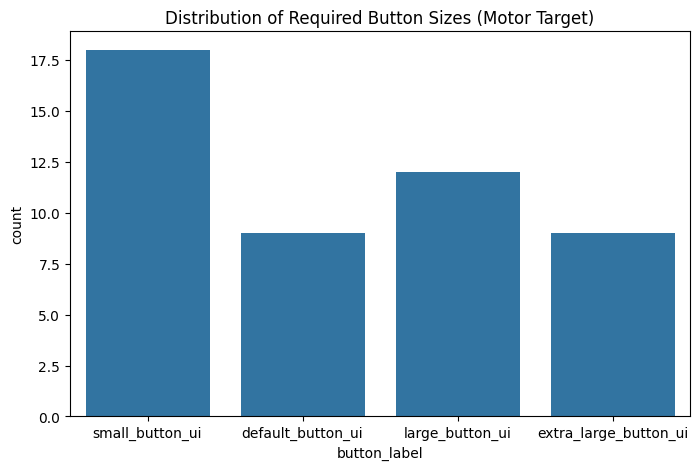


--- [STEP 3] Preprocessing ---
Preprocessing Complete. Features extracted: ['age', 'screen_width', 'screen_height', 'total_taps', 'successful_taps', 'miss_taps', 'tap_accuracy', 'avg_reaction_time_ms', 'miss_rate', 'IFI']

--- [STEP 4] Train/Test Split ---
Training set: (38, 10), Test set: (10, 10)

--- [STEP 5, 7, 8] Training and Evaluation ---
Training Decision Tree...
Training Random Forest...
Training XGBoost Base...
Training MLP Classifier...

--- [STEP 6] Hyperparameter Tuning for XGBoost ---
Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}

--- [STEP 9] Model Comparison ---
            Model  CV_Accuracy    CV_Std  Test_Accuracy  Balanced_Accuracy  \
0   Decision Tree     0.975000  0.050000            1.0              1.000   
2    XGBoost Base     0.950000  0.061237            1.0              1.000   
4   XGBoost Tuned     0.921429  0.064484            1.0              1.000   
1   Random Forest     0.871429  0.112031            

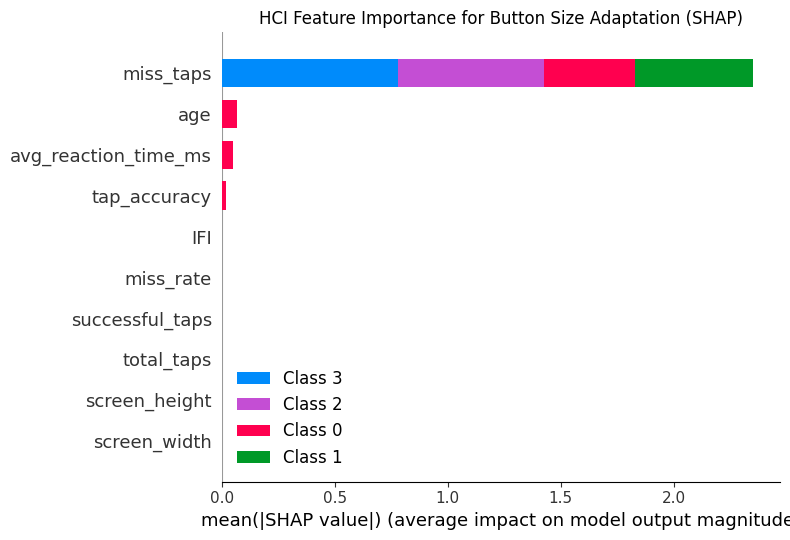


--- [STEP 12 & 13] Saving Models and Pipeline ---
Artifacts saved successfully.


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from datetime import datetime

# ML & Scikit-Learn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
                             confusion_matrix, classification_report, log_loss)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

# Explainability
import shap

warnings.filterwarnings('ignore')

class AUI_ButtonSize_Pipeline:
    def __init__(self, csv_path=None):
        self.csv_path = csv_path  # Fixed syntax error here
        self.df = None
        self.target_col = 'button_label'
        self.models = {}
        self.results = {}
        self.best_model = None
        
        # Artifacts
        self.label_encoder = LabelEncoder()
        self.scaler = StandardScaler()
        self.features = []

    # ==========================================
    # STEP 1 & 2: Load Data and EDA
    # ==========================================
    def load_and_eda(self):
        """Loads dataset and performs comprehensive Exploratory Data Analysis."""
        print("--- [STEP 1 & 2] Loading Data and Performing EDA ---")
        if self.csv_path:
            self.df = pd.read_csv(self.csv_path)  # Fixed variable reference here
        else:
            print("[INFO] No CSV provided.")
            return

        # EDA execution
        print(f"Dataset Shape: {self.df.shape}")
        print(f"Missing Values:\n{self.df.isnull().sum()}")
        print(f"Target Distribution:\n{self.df[self.target_col].value_counts(normalize=True)}")
        
        # Plotting distributions (HCI behavior focus)
        plt.figure(figsize=(8, 5))
        sns.countplot(x=self.target_col, data=self.df)
        plt.title("Distribution of Required Button Sizes (Motor Target)")
        plt.show()

    # ==========================================
    # STEP 3: Preprocessing
    # ==========================================
    def preprocess_data(self):
        """Handles missing values, encodes targets, and scales HCI features."""
        print("\n--- [STEP 3] Preprocessing ---")
        if self.df is None: return None, None
        
        df_clean = self.df.copy()
        numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
        df_clean[numeric_cols] = df_clean[numeric_cols].fillna(df_clean[numeric_cols].median())

        if 'user_id' in df_clean.columns:
            df_clean = df_clean.drop('user_id', axis=1)

        y = self.label_encoder.fit_transform(df_clean[self.target_col])
        X = df_clean.drop(self.target_col, axis=1)
        self.features = X.columns.tolist()

        X_scaled = pd.DataFrame(self.scaler.fit_transform(X), columns=self.features)
        
        print("Preprocessing Complete. Features extracted:", self.features)
        return X_scaled, y

    # ==========================================
    # STEP 4: Train/Test Split
    # ==========================================
    def split_data(self, X, y):
        print("\n--- [STEP 4] Train/Test Split ---")
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.20, stratify=y, random_state=42
        )
        print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")
        return X_train, X_test, y_train, y_test

    # ==========================================
    # STEP 5 & 7 & 8: Train, Cross-Validate, Evaluate
    # ==========================================
    def evaluate_model(self, model, X_train, y_train, X_test, y_test, model_name):
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        cv_scores = []
        
        X_tr_arr = X_train.values if isinstance(X_train, pd.DataFrame) else X_train
        y_tr_arr = y_train.values if isinstance(y_train, pd.Series) else y_train
        
        for train_idx, val_idx in skf.split(X_tr_arr, y_tr_arr):
            clone_model = type(model)(**model.get_params())
            clone_model.fit(X_tr_arr[train_idx], y_tr_arr[train_idx])
            cv_scores.append(clone_model.score(X_tr_arr[val_idx], y_tr_arr[val_idx]))
        
        import time
        start_time = time.time()
        model.fit(X_train, y_train)
        train_time = time.time() - start_time
        
        start_time = time.time()
        y_pred = model.predict(X_test)
        pred_time = time.time() - start_time

        acc = accuracy_score(y_test, y_pred)
        bal_acc = balanced_accuracy_score(y_test, y_pred)
        mcc = matthews_corrcoef(y_test, y_pred)
        kappa = cohen_kappa_score(y_test, y_pred)
        
        metrics = {
            "Model": model_name,
            "CV_Accuracy": np.mean(cv_scores),
            "CV_Std": np.std(cv_scores),
            "Test_Accuracy": acc,
            "Balanced_Accuracy": bal_acc,
            "F1_Weighted": f1_score(y_test, y_pred, average='weighted'),
            "Precision": precision_score(y_test, y_pred, average='weighted'),
            "Recall": recall_score(y_test, y_pred, average='weighted'),
            "MCC": mcc,
            "Cohen_Kappa": kappa,
            "Train_Time(s)": train_time,
            "Pred_Time(s)": pred_time
        }
        
        self.results[model_name] = metrics
        return model, y_pred

    def train_all_models(self, X_train, y_train, X_test, y_test):
        print("\n--- [STEP 5, 7, 8] Training and Evaluation ---")
        
        models_to_train = {
            "Decision Tree": DecisionTreeClassifier(random_state=42),
            "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
            "XGBoost Base": XGBClassifier(eval_metric='mlogloss', random_state=42),
            "MLP Classifier": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
        }

        for name, clf in models_to_train.items():
            print(f"Training {name}...")
            trained_model, _ = self.evaluate_model(clf, X_train, y_train, X_test, y_test, name)
            self.models[name] = trained_model

    # ==========================================
    # STEP 6: XGBoost Hyperparameter Tuning
    # ==========================================
    def tune_xgboost(self, X_train, y_train):
        print("\n--- [STEP 6] Hyperparameter Tuning for XGBoost ---")
        xgb_clf = XGBClassifier(eval_metric='mlogloss', random_state=42)
        
        param_grid = {
            'max_depth': [3, 5, 7],
            'learning_rate': [0.01, 0.1, 0.2],
            'n_estimators': [100, 200],
            'subsample': [0.8, 1.0]
        }
        
        grid_search = GridSearchCV(estimator=xgb_clf, param_grid=param_grid, 
                                   cv=StratifiedKFold(n_splits=3), scoring='f1_weighted', n_jobs=-1)
        grid_search.fit(X_train, y_train)
        
        print(f"Best Parameters: {grid_search.best_params_}")
        best_xgb = grid_search.best_estimator_
        self.models['XGBoost Tuned'] = best_xgb
        self.best_model = best_xgb
        return best_xgb

    # ==========================================
    # STEP 9: Model Comparison
    # ==========================================
    def compare_models(self):
        print("\n--- [STEP 9] Model Comparison ---")
        df_results = pd.DataFrame(self.results.values())
        print(df_results.sort_values(by="F1_Weighted", ascending=False))
        return df_results

    # ==========================================
    # STEP 10: Explainability (SHAP for AUI)
    # ==========================================
    def explain_model(self, X_train):
        print("\n--- [STEP 10] SHAP Explainability ---")
        explainer = shap.TreeExplainer(self.best_model)
        shap_values = explainer.shap_values(X_train)
        
        plt.figure(figsize=(10, 6))
        shap.summary_plot(shap_values, X_train, plot_type="bar", show=False)
        plt.title("HCI Feature Importance for Button Size Adaptation (SHAP)")
        plt.tight_layout()
        plt.show()

    # ==========================================
    # STEP 12 & 13: Export Artifacts
    # ==========================================
    def export_pipeline(self):
        print("\n--- [STEP 12 & 13] Saving Models and Pipeline ---")
        joblib.dump(self.best_model, 'xgboost_aui_model.pkl')
        joblib.dump(self.label_encoder, 'label_encoder.pkl')
        joblib.dump(self.scaler, 'feature_scaler.pkl')
        
        with open('features_list.txt', 'w') as f:
            for item in self.features:
                f.write("%s\n" % item)
        print("Artifacts saved successfully.")

# ==========================================
# EXECUTION BLOCK
# ==========================================
if __name__ == "__main__":
    # আপনার CSV ফাইলের সঠিক নামটি এখানে দিন (যেমন: dummy_button_dataset.csv)
    pipeline = AUI_ButtonSize_Pipeline(csv_path="dummy_button_dataset.csv")
    
    pipeline.load_and_eda()
    X, y = pipeline.preprocess_data()
    
    if X is not None:
        X_train, X_test, y_train, y_test = pipeline.split_data(X, y)
        pipeline.train_all_models(X_train, y_train, X_test, y_test)
        
        # Tune and re-evaluate XGBoost
        best_xgb = pipeline.tune_xgboost(X_train, y_train)
        pipeline.evaluate_model(best_xgb, X_train, y_train, X_test, y_test, "XGBoost Tuned")
        
        # Final steps
        pipeline.compare_models()
        pipeline.explain_model(X_train)
        pipeline.export_pipeline()

In [25]:
# ==========================================
# Predict Button Size for New User
# ==========================================

def predict_button_size(self,
                        age,
                        screen_width,
                        screen_height,
                        total_taps,
                        successful_taps,
                        miss_taps,
                        tap_accuracy,
                        avg_reaction_time_ms,
                        miss_rate,
                        IFI):

    import pandas as pd

    sample = pd.DataFrame([{
        "age": age,
        "screen_width": screen_width,
        "screen_height": screen_height,
        "total_taps": total_taps,
        "successful_taps": successful_taps,
        "miss_taps": miss_taps,
        "tap_accuracy": tap_accuracy,
        "avg_reaction_time_ms": avg_reaction_time_ms,
        "miss_rate": miss_rate,
        "IFI": IFI
    }])

    # Scale using trained scaler
    sample_scaled = self.scaler.transform(sample)

    # Predict
    pred = self.best_model.predict(sample_scaled)

    # Convert numeric label back to original label
    label = self.label_encoder.inverse_transform(pred)

    print("\n==============================")
    print(" Predicted Button Size")
    print("==============================")
    print("Recommendation :", label[0])
    print("==============================")

    return label[0]

In [29]:
dir(pipeline)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 'best_model',
 'compare_models',
 'csv_path',
 'df',
 'evaluate_model',
 'explain_model',
 'export_pipeline',
 'features',
 'label_encoder',
 'load_and_eda',
 'models',
 'preprocess_data',
 'results',
 'scaler',
 'split_data',
 'target_col',
 'train_all_models',
 'tune_xgboost']

In [31]:
print(type(pipeline.best_model))

<class 'xgboost.sklearn.XGBClassifier'>


In [32]:
import pandas as pd

# Dummy Input
sample = pd.DataFrame([{
    "age": 23,
    "screen_width": 1080,
    "screen_height": 2400,
    "total_taps": 50,
    "successful_taps": 45,
    "miss_taps": 5,
    "tap_accuracy": 0.90,
    "avg_reaction_time_ms": 340,
    "miss_rate": 0.10,
    "IFI": 0.17
}])

# Scale
sample_scaled = pipeline.scaler.transform(sample)

# Predict
pred = pipeline.best_model.predict(sample_scaled)

# Decode label
label = pipeline.label_encoder.inverse_transform(pred)

print("="*50)
print("Recommended Button Size :", label[0])
print("="*50)

# Probability
if hasattr(pipeline.best_model, "predict_proba"):
    probs = pipeline.best_model.predict_proba(sample_scaled)[0]

    print("\nConfidence:")

    for cls, p in zip(pipeline.label_encoder.classes_, probs):
        print(f"{cls:25s} : {p*100:.2f}%")

Recommended Button Size : default_button_ui

Confidence:
default_button_ui         : 47.10%
extra_large_button_ui     : 17.43%
large_button_ui           : 17.83%
small_button_ui           : 17.64%
